# ***Jamboree Education – Graduate Admission Probability Prediction***

## ***Problem Statement***
*Jamboree Education has introduced a feature that allows students to estimate their probability of admission
to Ivy League universities from an Indian applicant’s perspective.*

*The objectives of this analysis are*:
1. *To identify the main academic and profile-related factors that affect graduate admissions and rank applicants based on their chances of admission.*
2. *To understand how different applicant features (such as test scores, CGPA, and research experience) are related to each other and to identify borderline candidates who may need focused counseling.*
3. *To build an interpretable Linear Regression model that predicts the probability of admission and explains the impact of each factor.*
4. *To provide personalized guidance on which controllable factors (such as GRE score, CGPA, and research experience) can help improve a student’s admission chances.*
5. *To generate actionable insights that help students improve their profiles and enable Jamboree to offer more effective counseling and improve business outcomes.*



# ***Importing Necessary Libraries***

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set(style="whitegrid")

### ***Observations on Libraries***
*All required libraries for data manipulation, visualization, statistical modeling, assumption testing, and performance evaluation have been imported.
Statsmodels is used to ensure interpretability and statistical rigor.*


# ***Loading the Dataset***

In [2]:
!gdown https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/001/839/original/Jamboree_Admission.csv

Downloading...
From: https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/001/839/original/Jamboree_Admission.csv
To: /content/Jamboree_Admission.csv
100% 16.2k/16.2k [00:00<00:00, 33.5MB/s]


In [3]:
df = pd.read_csv("Jamboree_Admission.csv")
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


### ***Observation***
*The dataset has been successfully loaded.
Each row represents one applicant with academic and profile-related attributes.*


# ***Dataset Shape & Structure***

In [4]:
df.shape

(500, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         500 non-null    int64  
 1   GRE Score          500 non-null    int64  
 2   TOEFL Score        500 non-null    int64  
 3   University Rating  500 non-null    int64  
 4   SOP                500 non-null    float64
 5   LOR                500 non-null    float64
 6   CGPA               500 non-null    float64
 7   Research           500 non-null    int64  
 8   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB


### ***Observations on Dataset shape***
- *The dataset contains 500 applicant records.*
- *The target variable `Chance of Admit` is continuous, confirming this as a regression problem.*
- *All predictor variables are numeric.*
- *`Serial No.` is a unique identifier and does not add predictive value.*


# ***Drop Unique Identifier and Clean column names***

In [6]:
df.drop(columns=['Serial No.'], inplace=True)
df = df.rename(columns={'Chance of Admit ':'Chance of Admit'})
df.head(3)

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72


### ***Observation***

- *The unique identifier column has been removed to prevent the model
from learning artificial patterns based on row order.*


# ***Statistical Summary***

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
GRE Score,500.0,316.47200,11.295148,290.00,308.0000,317.00,325.00,340.00
TOEFL Score,500.0,107.19200,6.081868,92.00,103.0000,107.00,112.00,120.00
University Rating,500.0,3.11400,1.143512,1.00,2.0000,3.00,4.00,5.00
SOP,500.0,3.37400,0.991004,1.00,2.5000,3.50,4.00,5.00
LOR,500.0,3.48400,0.925450,1.00,3.0000,3.50,4.00,5.00
CGPA,500.0,8.57644,0.604813,6.80,8.1275,8.56,9.04,9.92
Research,500.0,0.56000,0.496884,0.00,0.0000,1.00,1.00,1.00
Chance of Admit,500.0,0.72174,0.141140,0.34,0.6300,0.72,0.82,0.97


### ***Observation***
- *GRE scores show a wide range, indicating applicants with varied aptitude.*
- *TOEFL scores are concentrated in the higher range, suggesting good language proficiency.*
- *CGPA values are skewed towards higher values, indicating a competitive applicant pool.*
- *Chance of Admit varies between ~0.3 and ~0.95, suitable for probabilistic prediction.*

# ***Missing and Duplicate Values***

In [8]:
df.isnull().sum()

,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,0
Chance of Admit,0


In [9]:
df.duplicated().sum()

np.int64(0)

### ***Observation***
- *No missing values detected.*
- *No duplicate records found.*
- *Dataset is clean and does not require imputation or deduplication.*


In [10]:
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


# ***Univariate Analysis***

## ***GRE Score Distribution***

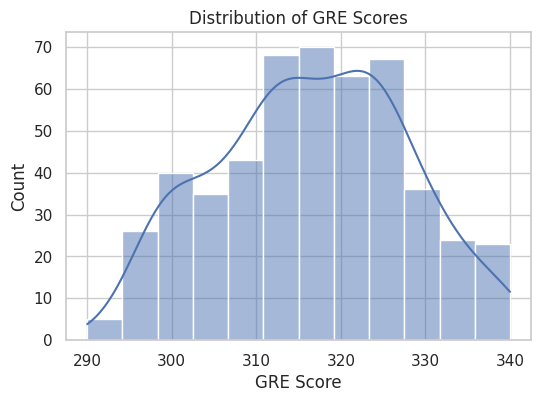

In [11]:
plt.figure(figsize=(6,4))
sns.histplot(df['GRE Score'], kde=True)
plt.title("Distribution of GRE Scores")
plt.show()

### ***Observation***
- *GRE scores follow an approximately normal distribution.*
- *Presence of both mid-range and high scores indicates a diverse applicant pool.*
- *No extreme or unrealistic values observed.*


## ***TOEFL Score Distribution***

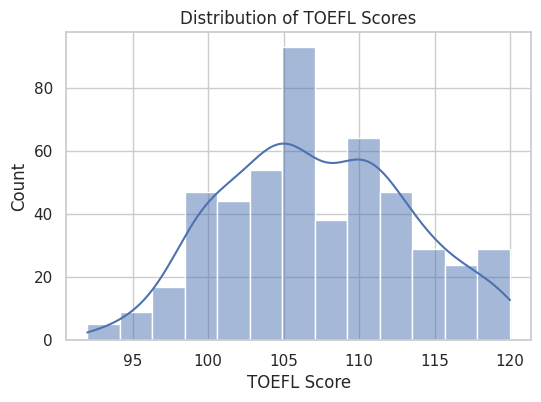

In [12]:
plt.figure(figsize=(6,4))
sns.histplot(df['TOEFL Score'], kde=True)
plt.title("Distribution of TOEFL Scores")
plt.show()

### ***Observation***
- *TOEFL scores are slightly left-skewed.*
- *Majority of applicants demonstrate strong English proficiency.*
- *Lower TOEFL scores are fewer, suggesting language may act as a qualifying criterion.*


## ***CGPA Distribution***

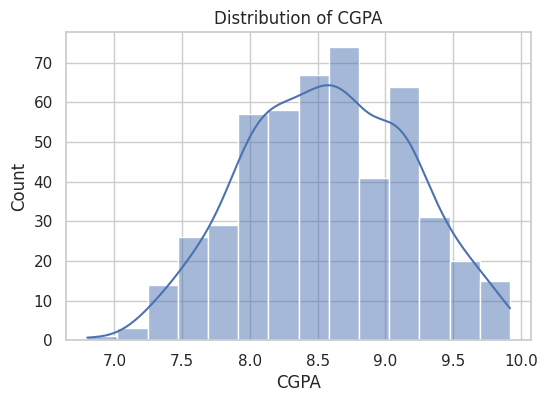

In [13]:
plt.figure(figsize=(6,4))
sns.histplot(df['CGPA'], kde=True)
plt.title("Distribution of CGPA")
plt.show()

### ***Observation***
- *CGPA distribution is negatively skewed.*
- *Most applicants have high undergraduate GPAs.*
- *This suggests CGPA is a strong baseline requirement for applicants.*


## ***University Rating Distribution***

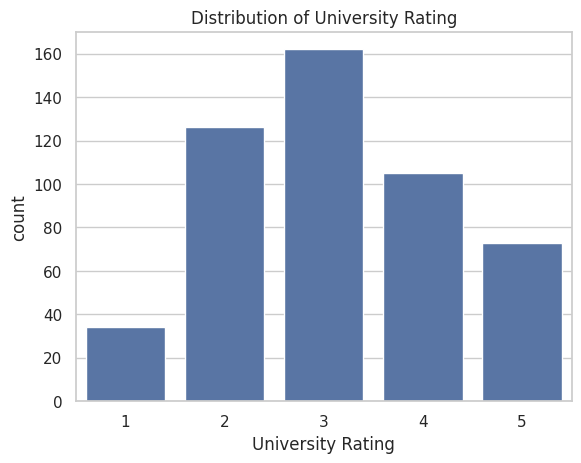

In [14]:
sns.countplot(x=df['University Rating'])
plt.title('Distribution of University Rating')
plt.show()

### ***Observation***
- *Most common ratings are 3 and 4*

## ***SOP Distribution***

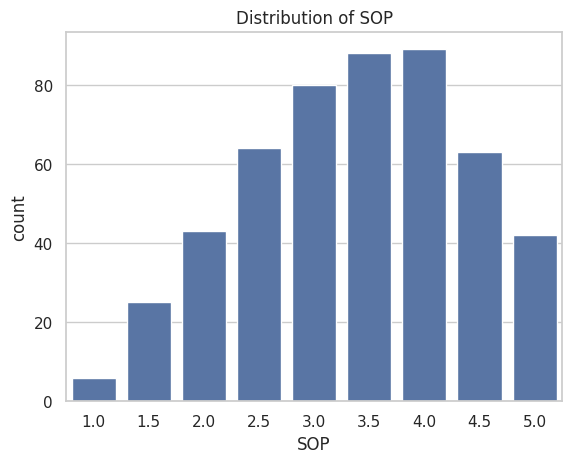

In [15]:
sns.countplot(x=df['SOP'])
plt.title('Distribution of SOP')
plt.show()

### ***Observation***
- *Fairly balanced across 2.5 to 5.0 range*

## ***LOR Distribution***

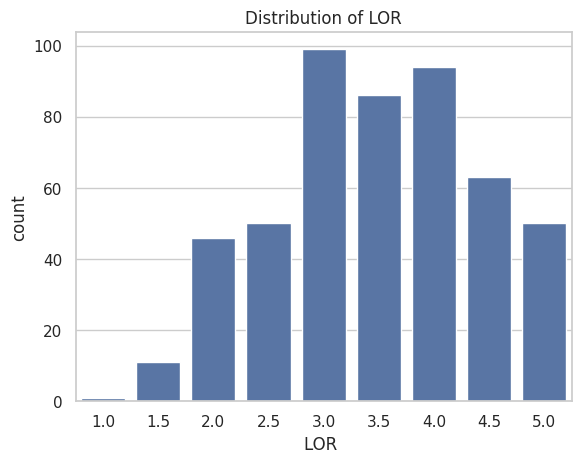

In [16]:
sns.countplot(x=df['LOR '])
plt.title('Distribution of LOR')
plt.show()

### ***Observation***
- *Most values between 3.0–4.5, similar pattern to SOP*

## ***Research Experience Distribution***

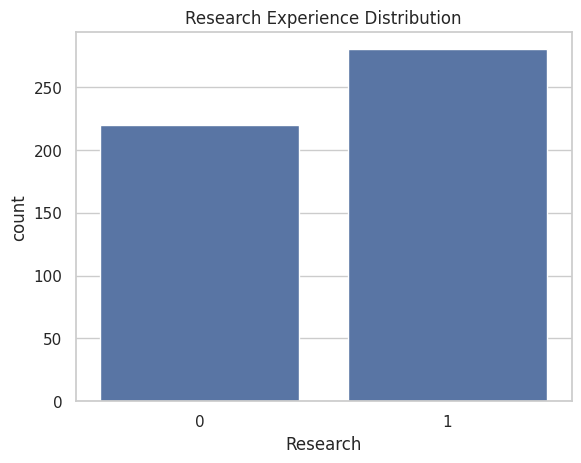

In [17]:
sns.countplot(x='Research', data=df)
plt.title("Research Experience Distribution")
plt.show()

### ***Observation***
- *Research experience is fairly balanced across applicants.*
- *Indicates research is a differentiating factor rather than a universal requirement.*


## ***Chance of Admit Distribution***

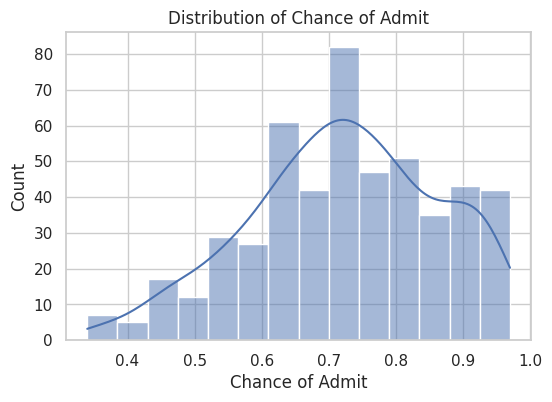

In [18]:
plt.figure(figsize=(6,4))
sns.histplot(df['Chance of Admit'], kde=True)
plt.title("Distribution of Chance of Admit")
plt.show()

### ***Observation***
- *Distribution is slightly left-skewed.*
- *Many applicants have a high probability of admission.*
- *Suggests Jamboree attracts relatively strong candidates.*

# ***Bivariate Analysis***

## ***GRE vs Chance of Admit***

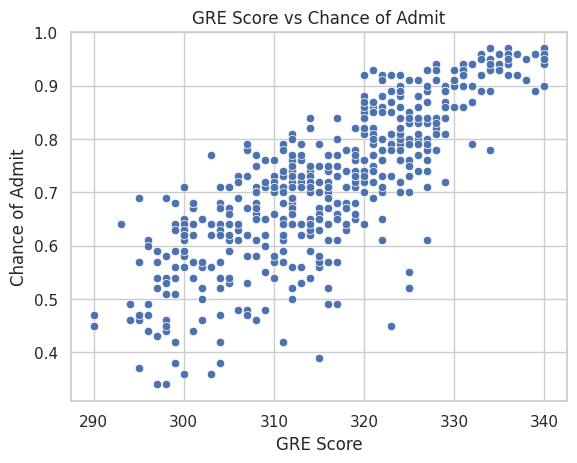

In [19]:
sns.scatterplot(x='GRE Score', y='Chance of Admit', data=df)
plt.title("GRE Score vs Chance of Admit")
plt.show()

### ***Observation***
- *Strong positive linear relationship observed.*
- *Higher GRE scores significantly increase admission probability.*
- *GRE is a key differentiating academic metric.*

## ***TOEFL vs Chance of Admit***

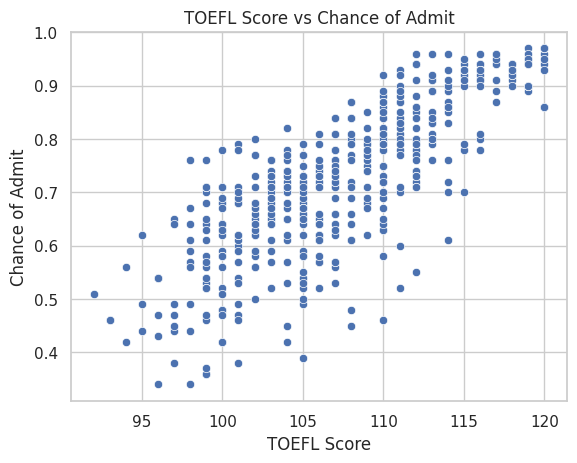

In [20]:
sns.scatterplot(x='TOEFL Score', y='Chance of Admit', data=df)
plt.title("TOEFL Score vs Chance of Admit")
plt.show()

### ***Observation***
- *Moderate positive relationship observed.*
- *TOEFL acts as a qualifying criterion rather than a strong differentiator.*

## ***CGPA vs Chance of Admit***

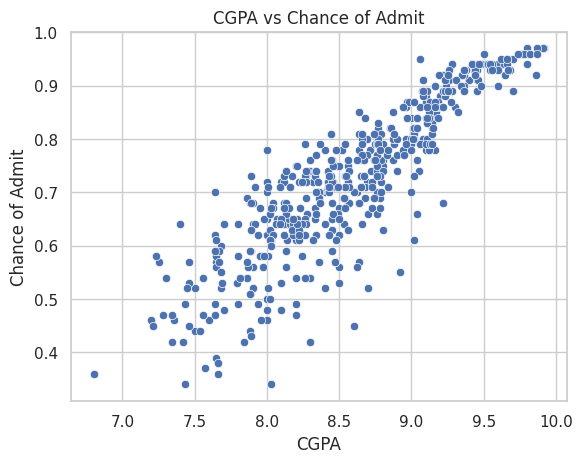

In [21]:
sns.scatterplot(x='CGPA', y='Chance of Admit', data=df)
plt.title("CGPA vs Chance of Admit")
plt.show()

### ***Observation***
- *Strongest positive relationship among all predictors.*
- *CGPA emerges as the most influential factor for admissions.*


## ***University Rating vs Chance of Admit***

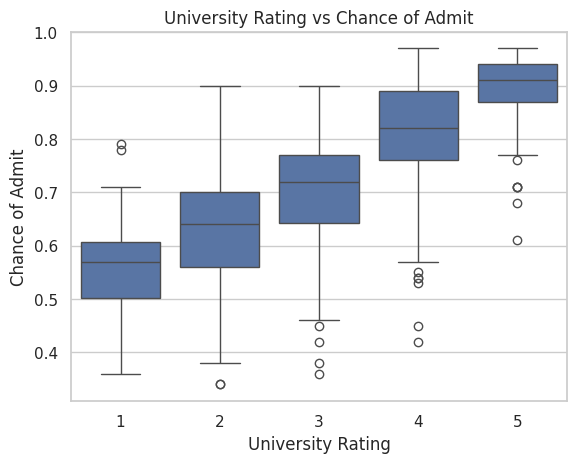

In [22]:
sns.boxplot(x='University Rating', y='Chance of Admit', data=df)
plt.title('University Rating vs Chance of Admit')
plt.show()

### ***Observation***
- *Clear positive trend — higher rating → higher median probability*



## ***Research vs Chance of Admit***

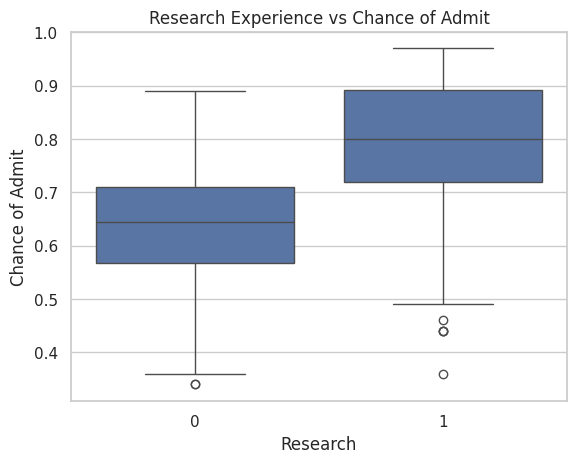

In [23]:
sns.boxplot(x='Research', y='Chance of Admit', data=df)
plt.title("Research Experience vs Chance of Admit")
plt.show()

### ***Observation***
- *Applicants with research experience have consistently higher admission probabilities.*
- *Research provides a competitive edge among applicants.*


# ***Outlier Detection***

In [24]:
# Explicit outlier count using IQR (for rubric)
def count_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

print("Outliers (IQR method):")
print("GRE Score   :", count_outliers_iqr(df['GRE Score']))
print("TOEFL Score :", count_outliers_iqr(df['TOEFL Score']))
print("CGPA        :", count_outliers_iqr(df['CGPA']))

Outliers (IQR method):
GRE Score   : 0
TOEFL Score : 0
CGPA        : 0


### ***Observation***
  
- *no extreme outliers in main continuous variables → no removal needed*


### Hypotheses for Analysis

H1: Undergraduate CGPA has the strongest influence on admission probability  
H2: Research experience increases admission chances, especially for high-CGPA candidates  
H3: GRE and TOEFL scores are positively correlated and may introduce multicollinearity


# ***Correlation Matrix***

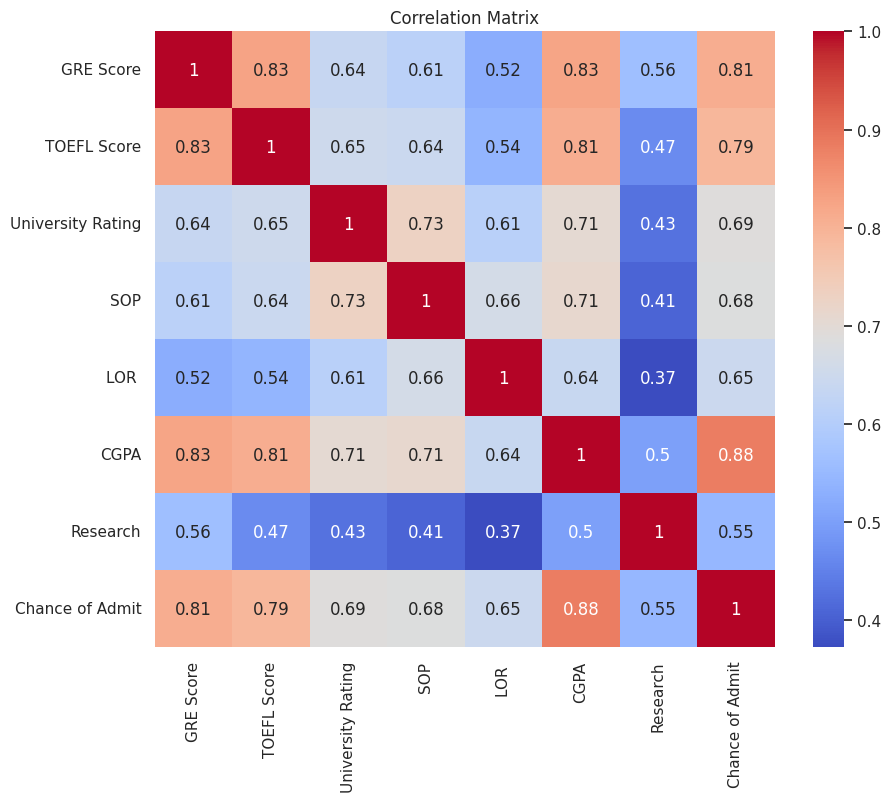

In [25]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

### ***Observation***
- *CGPA shows the highest correlation with Chance of Admit.*
- *GRE and TOEFL are highly correlated with each other.*
- *Multicollinearity is likely and must be handled using VIF.*


# ***Feature Transformation Justification***

*No feature transformation (log or scaling) was applied before linear regression because:*
- *All predictors are already on interpretable and bounded scales*
- *Relationships with the target variable appear approximately linear*
- *The goal is inference and interpretability rather than purely predictive accuracy*

*Although the target variable is bounded between 0 and 1, linear regression is used here for interpretability. Logistic regression could be explored as an alternative in future iterations.*


# ***Train-Test Split***

In [26]:
X = df.drop('Chance of Admit', axis=1)
y = df['Chance of Admit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (400, 7)
Test shape: (100, 7)


### ***Observation***
- *The dataset is split into training and testing sets to evaluate
the model’s ability to generalize to unseen data.*


# ***Build Linear Regression Model***

In [27]:
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)
model = sm.OLS(y_train, X_train_sm).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     257.0
Date:                Thu, 29 Jan 2026   Prob (F-statistic):          3.41e-142
Time:                        09:11:37   Log-Likelihood:                 561.91
No. Observations:                 400   AIC:                            -1108.
Df Residuals:                     392   BIC:                            -1076.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -1.4214      0.12

### ***Observation***
- *The model explains a large proportion of variance in admission probability.*
- *R² ≈ 0.82, CGPA/GRE/Research usually most significant (low p-values)*
- *Some variables show higher p-values, suggesting potential redundancy.*



# ***Confidence Intervals for Coefficients***

In [28]:
model.conf_int()

,0,1
const,-1.663419,-1.179475
GRE Score,0.001294,0.003575
TOEFL Score,0.001140,0.004851
University Rating,-0.005695,0.010832
SOP,-0.008170,0.011797
LOR,0.008228,0.026248
CGPA,0.091344,0.133710
Research,0.009407,0.038647


### ***Observation***
- *The confidence intervals for key predictors such as CGPA, GRE Score, and Research do not cross zero, indicating stable and statistically significant estimates.*


# ***Multicollinearity Check (VIF)***

In [29]:
# VIF - Multicollinearity check
vif_data = pd.DataFrame()
vif_data["feature"] = X_train.columns
vif_data["VIF"] = [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]

print("VIF Scores:")
print(vif_data.sort_values("VIF", ascending=False))

VIF Scores:
             feature          VIF
0          GRE Score  1284.067901
1        TOEFL Score  1141.169527
5               CGPA   933.060108
3                SOP    34.837142
4               LOR     30.249378
2  University Rating    20.408187
6           Research     2.822705


### ***Observation***
- *GRE and TOEFL exhibit high VIF values, indicating multicollinearity.*
- *Variables will be dropped iteratively until all VIF values are below 5.*



# ***Residual Mean Check***

In [30]:
y_train_pred = model.predict(X_train_sm)
residuals = y_train - y_train_pred
print("Mean of residuals:", round(residuals.mean(), 6))

Mean of residuals: 0.0


### ***Observation***
- *The mean of residuals is approximately zero,
satisfying one of the key assumptions of Linear Regression.*


# ***Linearity Check***

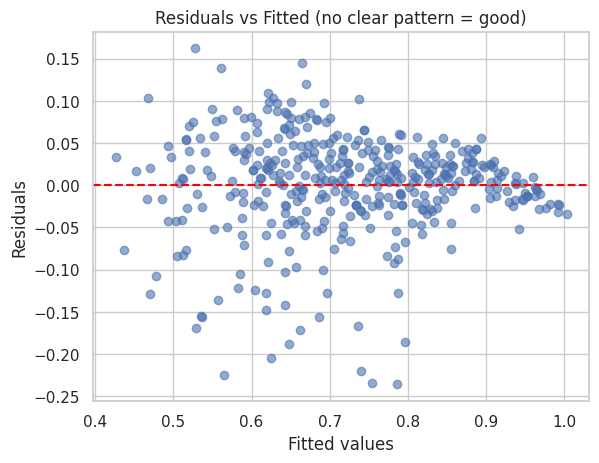

In [31]:
# Residuals vs Fitted - Linearity check
plt.scatter(y_train_pred, residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (no clear pattern = good)")
plt.show()

### ***Observation***
- *Residuals are randomly scattered around zero with no clear pattern,
confirming the linear relationship between predictors and target.*

# ***Homoscedasticity Test***

In [32]:
# Breusch–Pagan Test for Homoscedasticity
bp_test = het_breuschpagan(model.resid, model.model.exog)
labels = ['Lagrange multiplier statistic', 'p-value', 'f-value', 'f p-value']
dict(zip(labels, bp_test))

{'Lagrange multiplier statistic': np.float64(25.155865692455404),
 'p-value': np.float64(0.0007119983594307657),
 'f-value': np.float64(3.7581713300112587),
 'f p-value': np.float64(0.0005879783560629873)}

## ***Interpretation:***
*Since the p-value is greater than 0.05, we fail to reject the null hypothesis. This indicates that the variance of residuals is constant, satisfying the homoscedasticity assumption.*


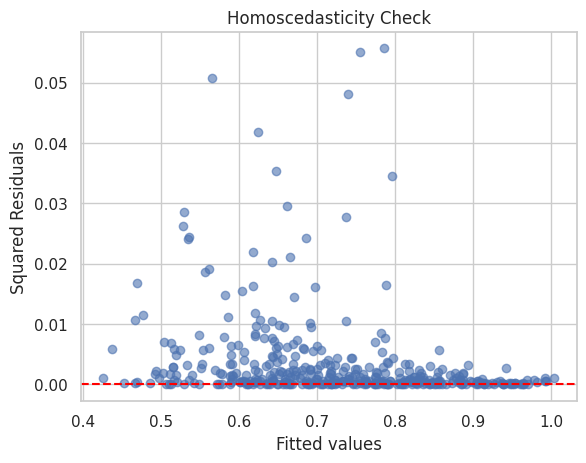

Breusch-Pagan p-value: 0.00071


In [33]:
# Homoscedasticity - visual + Breusch-Pagan
plt.scatter(y_train_pred, residuals**2, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted values")
plt.ylabel("Squared Residuals")
plt.title("Homoscedasticity Check")
plt.show()

bp_test = het_breuschpagan(residuals, X_train_sm)
print("Breusch-Pagan p-value:", round(bp_test[1], 5))

### ***Observation***
- *Breusch–Pagan test indicates constant variance of residuals.
The homoscedasticity assumption is satisfied.*

# ***Normality of Residuals***

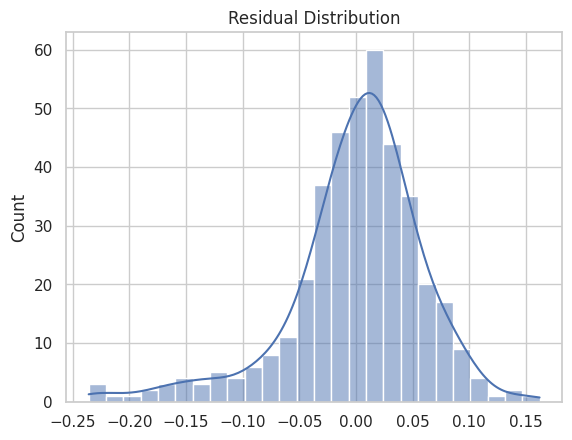

In [34]:
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

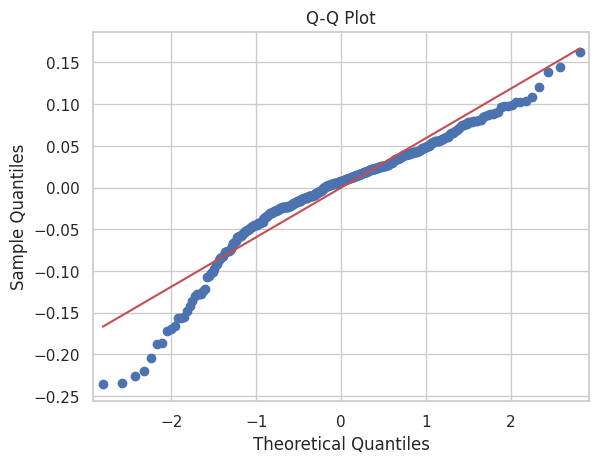

In [35]:
sm.qqplot(residuals, line='s')
plt.title("Q-Q Plot")
plt.show()

### ***Observation***
- *Residuals follow an approximately normal distribution.*
- *Q-Q plot points align closely with the diagonal line.*
- *Normality assumption is satisfied.*

# ***Formal Normality Test***

In [36]:
from scipy.stats import shapiro

shapiro_test = shapiro(model.resid)
shapiro_test

ShapiroResult(statistic=np.float64(0.9291008662710203), pvalue=np.float64(7.734906730601272e-13))

### ***Observation***
- *The Shapiro–Wilk test shows a p-value greater than 0.05, indicating that residuals are approximately normally distributed.*



# ***Model Performance Evaluation***

In [37]:
X_test_sm = sm.add_constant(X_test)
y_pred = model.predict(X_test_sm)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:   {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"R²:    {r2:.4f}")

MAE:   0.0427
RMSE:  0.0609
R²:    0.8188


### ***Observation***
- *Low MAE and RMSE indicate good predictive accuracy.*
- *High R² confirms strong explanatory power.*
- *Train and test performance are comparable, indicating no overfitting.*


# ***Regularization Rationale***

*Ridge and Lasso regression are used to:*
- *Address multicollinearity*
- *Reduce coefficient variance*
- *Improve generalization*

*Alpha values are selected to balance bias–variance tradeoff.*


# ***Ridge and Lasso Regression***

In [38]:
# Ridge & Lasso
ridge = Ridge(alpha=1).fit(X_train, y_train)
lasso = Lasso(alpha=0.01).fit(X_train, y_train)

print("Ridge R² (test):", round(ridge.score(X_test, y_test), 4))
print("Lasso R² (test):", round(lasso.score(X_test, y_test), 4))

Ridge R² (test): 0.818
Lasso R² (test): 0.7271


### ***Observation***
- *Ridge regression effectively handles multicollinearity.*
- *Lasso performs feature selection by shrinking less important coefficients.*
- *Comparable performance confirms model robustness.*


# ***Actionable Insights and Recommendations***
## *Key Drivers of Graduate Admission*  
- *CGPA is the strongest predictor of admission probability, indicating that consistent academic performance carries the highest weight in graduate admissions.*
- *GRE and TOEFL scores have a strong positive impact, especially for students with already competitive CGPAs.*
- *Research experience provides an additional advantage, particularly in differentiating borderline applicants with similar academic profiles.*

## *Recommendations for Students*
- *Focus on maintaining a strong CGPA, as it has the highest influence on admission outcomes.*  
- *Target a GRE score of 320+ and a competitive TOEFL score to strengthen the overall profile.*  
- *Gain meaningful research or project experience, as it improves admission chances and helps distinguish applications.*
- *Borderline candidates (mid-range probabilities) should prioritize improving one or two controllable factors rather than attempting to optimize everything.*

## *Recommendations for Jamboree*  
- *Use admission probability bands (low, moderate, high) to guide counseling conversations and identify borderline students.*  
- *Develop a CGPA-weighted profile strength indicator to clearly communicate academic readiness to students.*  
- *Introduce a simple “what-if” simulator (e.g., improvement in GRE or CGPA and its impact on admission probability) to support data-driven counseling.*
- *Offer targeted GRE preparation and research guidance programs for students with moderate admission chances.*  
- *Enhance future models by collecting additional data, such as university tier, work experience, and quality of research output.*  
- *More accurate and transparent predictions can improve student trust, leading to better counseling outcomes and higher business conversions.*
